# 🌱 Computer Vision — Real-World Data Preparation Project
### Session 05 | Student Assignment Notebook

**Project:** Prepare real bean-leaf images for a future CNN model  
**Final goal:** A clean, tested, model-ready image dataset — **no model training today**.

> **Project story:** An AgriTech team wants to build a system that can recognize healthy and diseased bean leaves. Your job is to inspect the real images, test image-processing ideas, and deliver reliable inputs for the ML engineer who will train the CNN.

---

### How to use this notebook

1. Read **Why this step matters** before running the code.
2. Run the starter examples to understand the data.
3. Complete every **🛠️ YOUR TASK** and `TODO` comment. **Do not skip code cells.**
4. Write short answers in **📝 Engineer's notes**. Explain your choice, not just the output.
5. Keep the original dataset unchanged while you experiment.
6. At the end, export your model-ready dataset and run the quality checks.

**Important:** This is a student starter notebook. Some functions intentionally raise `NotImplementedError` until you write your solution. That is part of your task.

## 🎯 Learning goals and project plan

By the end, you will be able to:

- Inspect a real image dataset and find possible quality problems.
- Explain pixels, channels, image shapes, and image data types.
- Convert images between RGB, Grayscale, Binary, and HSV.
- Use masks to select areas with a target color.
- Add *test noise* and compare Mean, Gaussian, and Median filters.
- Apply geometric transformations and explain when they help.
- Build one reusable preprocessing function.
- Keep **train**, **validation**, and **test** data separate and deliver arrays ready for a CNN.

| Stage | Your work | Expected output |
|---|---|---|
| 1 | Load and understand the data | Data overview |
| 2 | Data quality and EDA | Class counts, image examples, audit |
| 3 | Image types | RGB, Grayscale, Binary comparison |
| 4 | Color spaces | HSV channels and green masks |
| 5 | Image histogram | Brightness/contrast interpretation |
| 6 | Noise and filters | Visual and numeric comparison |
| 7 | Geometry and augmentation | Transformation gallery |
| 8 | Build the final preprocessing function | One tested function |
| 9 | Prepare and export the dataset | Arrays + labels + metadata |
| 10 | Quality checks and handoff | Final checklist + short report |

**Working rule:** Test ideas using copies of images. Do not permanently apply experimental noise, binary conversion, or green masks to your final CNN inputs.

## 0 — Setup: Prepare your workspace

### Why this step matters
A real project needs a clear environment, fixed settings, and repeatable results. If the team runs your notebook again, it should produce the same preprocessing steps.

**🛠️ YOUR TASK**
- Open this notebook in Google Colab or Jupyter.
- Run the installation cell once.
- Run the imports and configuration cells.
- Keep the random seed fixed.

In [1]:
# Step 0.1 — Install the required packages.
# In Google Colab, most of these packages may already exist.
%pip install -q datasets opencv-python-headless numpy pandas matplotlib pillow

In [2]:
# Step 0.2 — Import tools used during this project.
from datasets import load_dataset
from PIL import Image
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import json

# Set one fixed seed so random examples can be reproduced.
SEED = 42
rng = np.random.default_rng(SEED)

# We will use the same image size for the future CNN.
TARGET_SIZE = (224, 224)  # (width, height) for OpenCV
DATASET_ID = "AI-Lab-Makerere/beans"
EXPORT_DIR = Path("beans_model_ready")
EXPORT_DIR.mkdir(exist_ok=True)

print("OpenCV version:", cv2.__version__)
print("Target image size:", TARGET_SIZE)

OpenCV version: 5.0.0
Target image size: (224, 224)


## 1 — Load the real dataset

### Why this step matters
Before cleaning any data, you must know **where it comes from**, **what the labels mean**, and **how the dataset is divided**. This protects you from using the wrong data or creating data leakage.

**Dataset:** [Beans dataset — Makerere AI Lab on Hugging Face](https://huggingface.co/datasets/AI-Lab-Makerere/beans). It contains real bean-leaf images in three categories:

- `angular_leaf_spot`
- `bean_rust`
- `healthy`

It already provides `train`, `validation`, and `test` splits. **Keep those splits; do not merge them.** The first download needs internet access and may take a little while.

**🛠️ YOUR TASK**
1. Run the next cell and read the dataset structure.
2. Answer: What is one *feature*? What is a *label*?
3. Record how many images are in each split.

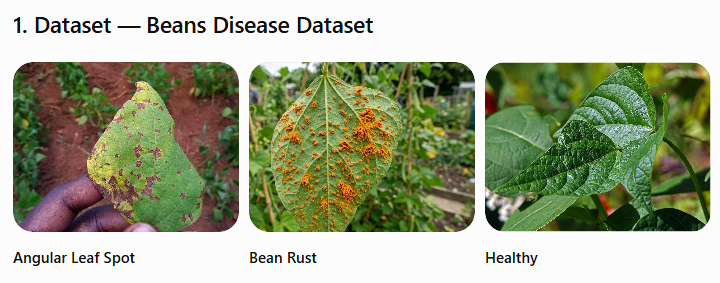

In [3]:
# Step 1.1 — Load the dataset from Hugging Face.
# Note: the internet is needed the first time.
dataset = load_dataset(DATASET_ID)

print(dataset)
print("Available splits:", list(dataset.keys()))

# Read the class names from the dataset metadata, not by guessing.
CLASS_NAMES = dataset["train"].features["labels"].names
CLASS_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}
print("Class names:", CLASS_NAMES)
print("Class-to-ID mapping:", CLASS_TO_ID)

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Available splits: ['train', 'validation', 'test']
Class names: ['angular_leaf_spot', 'bean_rust', 'healthy']
Class-to-ID mapping: {'angular_leaf_spot': 0, 'bean_rust': 1, 'healthy': 2}


Example fields: dict_keys(['image_file_path', 'image', 'labels'])
Example label ID: 0
Example label name: angular_leaf_spot
Array shape: (500, 500, 3)
Array dtype: uint8


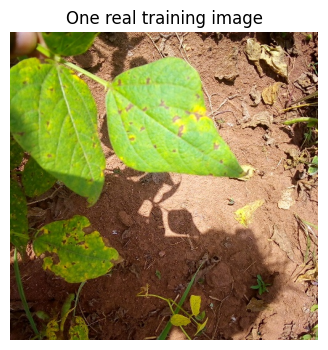

In [4]:
# Step 1.2 — Look at one example.
# Hugging Face image objects are usually decoded to PIL images.
example = dataset["train"][0]
print("Example fields:", example.keys())
print("Example label ID:", example["labels"])
print("Example label name:", CLASS_NAMES[example["labels"]])

# Convert to RGB to make the output predictable.
example_image = np.asarray(example["image"].convert("RGB"))
print("Array shape:", example_image.shape)
print("Array dtype:", example_image.dtype)

plt.figure(figsize=(5, 4))
plt.imshow(example_image)
plt.title("One real training image")
plt.axis("off")
plt.show()

**📝 Engineer's notes — Stage 1**

- **Input features:** `WRITE YOUR ANSWER`
- **Target label:** `WRITE YOUR ANSWER`
- **Number of images in train / validation / test:** `WRITE THE NUMBERS`
- **Why must we keep the test set separate?** `YOUR ANSWER`

**Checkpoint:** You understand what one row represents and what the future model should predict.

## 2 — Explore and audit the data (EDA)

### Why this step matters
A CNN cannot fix a broken dataset by itself. Before preprocessing, we need to know:

- Are some classes much larger than others?
- Do images have different sizes?
- Do we have unreadable images or unexpected image modes?
- Are labels clear and correctly mapped?

We will **inspect first**, then decide what processing is needed.

### Step 2.1 — Check class balance

**🛠️ YOUR TASK**

1. Count each class in each split.
2. Make a bar chart showing the class count in the **training** split.
3. Write a short observation: Is the training data balanced? Why does that matter?

**Hint:** `Counter(...)`, `CLASS_NAMES`, `plt.bar(...)`.

In [ ]:
# Starter: create a small class-count table.
class_count_rows = []
for split_name, split_data in dataset.items():
    counts = Counter(split_data["labels"])
    for class_id, class_name in enumerate(CLASS_NAMES):
        class_count_rows.append({
            "split": split_name,
            "class_name": class_name,
            "count": counts.get(class_id, 0),
        })

class_count_df = pd.DataFrame(class_count_rows)
display(class_count_df)

train_counts = class_count_df[class_count_df["split"] == "train"]
plt.figure(figsize=(8, 4))
plt.bar(train_counts["class_name"], train_counts["count"])
plt.title("Training images per class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 2.2 — Create an image gallery

### Why this step matters
Numbers do not show everything. A visual gallery helps us notice image quality, background changes, leaf position, and lighting conditions.

**🛠️ YOUR TASK**
- Show **9 random training images** in a 3×3 grid.
- Write each image's class name above it.
- Look for at least **two differences** between real images.

**Hint:** `rng.choice(...)`, `plt.subplots(3, 3)`, `axes.flat`, `imshow(...)`.

In [ ]:
# TODO 2.2 — Fill the missing lines in this gallery.
random_indices = rng.choice(len(dataset["train"]), size=9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for axis, row_index in zip(axes.flat, random_indices):
    item = dataset["train"][int(row_index)]
    image_array = np.asarray(item["image"].convert("RGB"))
    axis.imshow(image_array)
    axis.set_title(CLASS_NAMES[int(item["labels"])])
    axis.axis("off")

plt.suptitle("Random training images", fontsize=14)
plt.tight_layout()
plt.show()

### Step 2.3 — Inspect image sizes, channels, and modes

### Why this step matters
A batch of CNN inputs must have a consistent shape. Some image files might be RGB, grayscale, RGBA, or different sizes. We should **measure this before resizing**.

**🛠️ YOUR TASK**
- Review the table below.
- Report the minimum and maximum width and height.
- Check if there are images that are not RGB.
- Explain what can go wrong if we stack different image sizes directly.

In [ ]:
# This is a data audit, so it is OK to scan all split metadata.
image_audit = []
for split_name, split_data in dataset.items():
    for image_index, row in enumerate(split_data):
        pil_img = row["image"]
        image_audit.append({
            "split": split_name,
            "index": image_index,
            "width": pil_img.width,
            "height": pil_img.height,
            "mode": pil_img.mode,
            "label": CLASS_NAMES[int(row["labels"])],
        })

audit_df = pd.DataFrame(image_audit)
display(audit_df.head())
print("\nImage size summary:\n", audit_df[["width", "height"]].describe())
print("\nImage mode counts:\n", audit_df["mode"].value_counts())

plt.figure(figsize=(8, 4))
plt.hist(audit_df["width"], bins=15, edgecolor="black")
plt.title("Distribution of image widths")
plt.xlabel("Width (pixels)")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

### Step 2.4 — Find unreadable or invalid images

### Why this step matters
If one file is broken, your full preprocessing job may stop in the middle. A reliable engineering pipeline checks input quality and records problems.

**🛠️ YOUR TASK**
- Try to decode every image.
- Find empty images or unexpected arrays.
- Keep a list of issues (split, row, error).
- Do not silently delete a bad image. Explain the decision.

**Hint:** `try/except`, `np.asarray(...)`, `array.size`, `np.isfinite(...)`.

In [ ]:
# TODO 2.4 — Build a small input-integrity checker.
def audit_split_images(split_data, split_name):
    """Return a list of problems found while checking images."""
    issues = []
    for index in range(len(split_data)):
        try:
            pil_image = split_data[index]["image"]
            image_array = np.asarray(pil_image.convert("RGB"))
            if image_array.size == 0:
                issues.append({"split": split_name, "index": index, "error": "empty image array"})
            elif image_array.ndim != 3 or image_array.shape[2] != 3:
                issues.append({"split": split_name, "index": index, "error": f"unexpected shape {image_array.shape}"})
            elif not np.isfinite(image_array).all():
                issues.append({"split": split_name, "index": index, "error": "array contains NaN or Inf"})
        except Exception as error:
            issues.append({"split": split_name, "index": index, "error": str(error)})
    return issues

all_issues = []
for split_name in dataset.keys():
    all_issues.extend(audit_split_images(dataset[split_name], split_name))
print("Number of issues:", len(all_issues))
display(pd.DataFrame(all_issues).head())

**📝 Engineer's notes — Stage 2**

- **Class distribution:** `YOUR OBSERVATION`
- **Image sizes / modes:** `YOUR OBSERVATION`
- **Data quality issues found:** `YOUR OBSERVATION`
- **One risk for the future CNN:** `YOUR ANSWER`

**Checkpoint:** You have a short, evidence-based data quality report.

## 3 — Understand image types: RGB, Grayscale, Binary

### Why this step matters
Images are numbers. Different image types hold different information:

- **RGB:** Three color channels. Often useful for recognizing plant diseases.
- **Grayscale:** One intensity channel. Useful for understanding shapes, edges, and brightness.
- **Binary:** Two possible states. Useful for simple masks and threshold-based segmentation.

**Important:** For our final CNN, we plan to keep **RGB**. The following conversions are learning experiments, **not** final training-data replacements.

### Step 3.1 — Inspect one RGB pixel

**🛠️ YOUR TASK**
- Select a training image.
- Print its shape and one pixel's RGB values.
- Find its minimum and maximum pixel values.
- Explain what the three values represent.

In [ ]:
# Use the same sample to compare the image types.
selected_row = dataset["train"][15]
rgb_image = np.asarray(selected_row["image"].convert("RGB"))

print("RGB shape:", rgb_image.shape)
print("RGB dtype:", rgb_image.dtype)
print("Top-left pixel:", rgb_image[0, 0])
print("Minimum pixel value:", rgb_image.min())
print("Maximum pixel value:", rgb_image.max())
print("Red/Green/Blue at top-left:", rgb_image[0, 0, 0], rgb_image[0, 0, 1], rgb_image[0, 0, 2])

### Step 3.2 — Convert RGB to Grayscale

### Why this step matters
Grayscale removes color channels and keeps brightness information. It makes some image-processing algorithms simpler, but it also removes information that may be helpful to the CNN.

**🛠️ YOUR TASK**
- Convert the RGB image to Grayscale.
- Print its new shape.
- Plot RGB and Grayscale images next to each other.

**Hint:** `cv2.COLOR_RGB2GRAY` (do **not** use `COLOR_BGR2GRAY` here, because your NumPy image is RGB).

In [ ]:
# TODO 3.2 — Convert the RGB image to grayscale.
gray_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
print("Gray shape:", gray_image.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(rgb_image)
axes[0].set_title("RGB")
axes[0].axis("off")
axes[1].imshow(gray_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale")
axes[1].axis("off")
plt.tight_layout()
plt.show()

### Step 3.3 — Convert Grayscale to Binary

### Why this step matters
Thresholding is a simple way to separate bright and dark parts. It produces a binary result. This does **not** automatically identify sick leaves; it only checks a value against a threshold.

**🛠️ YOUR TASK**
- Use a threshold of **127**.
- Show Original RGB, Grayscale, and Binary in one row.
- Try a second threshold, such as **180**.
- Explain what changed.

**Hint:** `cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)`.

In [ ]:
# TODO 3.3 — Compare binary thresholds.
_, binary_127 = cv2.threshold(gray_image, 127, 255, cv2.THRESH_BINARY)
_, binary_180 = cv2.threshold(gray_image, 180, 255, cv2.THRESH_BINARY)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(rgb_image)
axes[0].set_title("RGB")
axes[0].axis("off")
axes[1].imshow(binary_127, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Binary threshold 127")
axes[1].axis("off")
axes[2].imshow(binary_180, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Binary threshold 180")
axes[2].axis("off")
plt.tight_layout()
plt.show()

**📝 Engineer's notes — Stage 3**

- **What information is lost after converting RGB to Grayscale?** `YOUR ANSWER`
- **What does a white pixel mean in your Binary output?** `YOUR ANSWER`
- **Which image type should we keep for the final plant disease CNN? Why?** `YOUR ANSWER`

## 4 — Explore color spaces: RGB and HSV

### Why this step matters
RGB stores colors using red, green, and blue intensities. HSV separates **Hue** (color family), **Saturation** (color purity), and **Value** (brightness). This can make color selection easier.

For 8-bit images, OpenCV's standard HSV format commonly uses:

| Channel | Range |
|---|---|
| H | 0–179 |
| S | 0–255 |
| V | 0–255 |

**Critical detail:** `cv2.cvtColor` needs the correct input color order. Our array is **RGB**, so use `COLOR_RGB2HSV`.

### Step 4.1 — Convert and inspect HSV channels

**🛠️ YOUR TASK**
- Convert an RGB bean image to HSV.
- Extract H, S, and V channels.
- Show the original RGB image and the three channels in a 2×2 grid.
- Print the value range in each channel.

In [ ]:
# One line is provided so you can focus on channel analysis.
hsv_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2HSV)
print("HSV shape:", hsv_image.shape)

h_channel = hsv_image[:, :, 0]
s_channel = hsv_image[:, :, 1]
v_channel = hsv_image[:, :, 2]

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes[0, 0].imshow(rgb_image)
axes[0, 0].set_title("RGB")
axes[0, 0].axis("off")
for axis, channel, title in zip(axes.flat[1:], [h_channel, s_channel, v_channel], ["Hue", "Saturation", "Value"]):
    axis.imshow(channel, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

for name, channel in [("H", h_channel), ("S", s_channel), ("V", v_channel)]:
    print(f"{name}: min={channel.min()}, max={channel.max()}")

### Step 4.2 — Create a green color mask

### Why this step matters
We can ask: "Which pixels look green?" A mask shows pixels inside a chosen color range. This is useful for understanding color segmentation, but a green region is **not** the same as a healthy leaf.

**🛠️ YOUR TASK**
1. Choose a reasonable lower and upper HSV range for green.
2. Make a binary mask using `cv2.inRange`.
3. Apply the mask to the RGB image using `cv2.bitwise_and`.
4. Show **Original / Mask / Masked RGB** side by side.
5. Adjust the limits if the mask includes too much background.

**Hint:** Start by experimenting with an H range near **35–85**, then choose S and V limits from **0–255**. These are starting points, not universal truth.

In [ ]:
# Green HSV range.
lower_green = np.array([35, 40, 40], dtype=np.uint8)
upper_green = np.array([85, 255, 255], dtype=np.uint8)

mask = cv2.inRange(hsv_image, lower_green, upper_green)
masked_rgb = cv2.bitwise_and(rgb_image, rgb_image, mask=mask)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(rgb_image)
axes[0].set_title("Original RGB")
axes[0].axis("off")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Green mask")
axes[1].axis("off")
axes[2].imshow(masked_rgb)
axes[2].set_title("Masked RGB")
axes[2].axis("off")
plt.tight_layout()
plt.show()

print("Green pixels:", np.mean(mask > 0) * 100, "%")

### Step 4.3 — Compare green masks across classes

**🛠️ YOUR TASK**
- Choose one image from **healthy**, one from **bean_rust**, and one from **angular_leaf_spot**.
- Apply the **same HSV bounds** to all three images.
- Make a comparison chart.
- Answer: Can a green mask alone tell us the disease class? What is its limitation?

**Hint:** Use `CLASS_TO_ID` to find examples from each class; use `next(...)` or filter indices.

In [ ]:
# TODO 4.3 — Create a small gallery of 3 classes using one shared green mask.
class_examples = {}
for row in dataset["train"]:
    label_id = int(row["labels"])
    if label_id not in class_examples:
        class_examples[label_id] = row
    if len(class_examples) == len(CLASS_NAMES):
        break

print("Found class examples:", [CLASS_NAMES[i] for i in class_examples])

fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(8, 12))
for row_index, label_id in enumerate(sorted(class_examples)):
    rgb = np.asarray(class_examples[label_id]["image"].convert("RGB"))
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv, lower_green, upper_green)
    axes[row_index, 0].imshow(rgb)
    axes[row_index, 0].set_title(CLASS_NAMES[label_id] + " — RGB")
    axes[row_index, 0].axis("off")
    axes[row_index, 1].imshow(mask, cmap="gray")
    axes[row_index, 1].set_title(CLASS_NAMES[label_id] + " — Mask")
    axes[row_index, 1].axis("off")
plt.tight_layout()
plt.show()

**📝 Engineer's notes — Stage 4**

- **My green HSV range:** `YOUR VALUES`
- **Why did I choose this range?** `YOUR ANSWER`
- **One reason a color mask may fail:** `YOUR ANSWER`
- **Should the final CNN receive the mask or the RGB image? Explain.** `YOUR ANSWER`

## 6 — Test noise and filters (controlled experiment)

### Why this step matters
Real photos may contain sensor noise, compression artifacts, or poor lighting. Filters can reduce noise, but can also remove disease details. In this experiment, you will **add known noise to a copy** and measure how well each filter recovers the clean image.

**Safety rule for the dataset:** This is an experiment only. **Do not replace the original data with noisy or filtered images** in the final dataset unless you have tested and justified it.

### Step 6.1 — Create two noisy copies

**🛠️ YOUR TASK**

1. Write `add_gaussian_noise(image, sigma, seed)`.
2. Write `add_salt_pepper_noise(image, amount, seed)`.
3. Show clean, Gaussian-noisy, and Salt-and-Pepper-noisy versions side by side.

**Hint for Gaussian:** sample random values with `rng.normal(...)`, add to a **float** copy, clip to `[0,255]`, convert back to `uint8`.

**Hint for Salt-and-Pepper:** choose random pixel positions; set some to black (`0`) and some to white (`255`). If your image has three channels, set all three values for each selected pixel.

Keep the functions reusable — they should work with any RGB image.

In [ ]:
# TODO 6.1 — Complete both functions.
def add_gaussian_noise(image, sigma=20, seed=42):
    """Return a NEW uint8 image with Gaussian noise."""
    local_rng = np.random.default_rng(seed)
    noise = local_rng.normal(0, sigma, size=image.shape)
    noisy = np.clip(image.astype(np.float32) + noise, 0, 255)
    return noisy.astype(np.uint8)


def add_salt_pepper_noise(image, amount=0.03, seed=42):
    """Return a NEW uint8 image with salt-and-pepper noise."""
    noisy = image.copy()
    local_rng = np.random.default_rng(seed)
    height, width = noisy.shape[:2]
    num_pixels = int(height * width * amount)
    positions = local_rng.choice(height * width, size=num_pixels, replace=False)
    rows, cols = np.unravel_index(positions, (height, width))
    split = num_pixels // 2
    noisy[rows[:split], cols[:split]] = 0
    noisy[rows[split:], cols[split:]] = 255
    return noisy

In [ ]:
# Step 6.1 test — Run after completing both functions.
clean_rgb = rgb_image.copy()
gaussian_noisy = add_gaussian_noise(clean_rgb, sigma=20, seed=SEED)
salt_pepper_noisy = add_salt_pepper_noise(clean_rgb, amount=0.03, seed=SEED)

assert np.array_equal(clean_rgb, rgb_image), "You changed the original image!"

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, image, title in zip(
    axes,
    [clean_rgb, gaussian_noisy, salt_pepper_noisy],
    ["Clean", "Gaussian noise", "Salt-and-pepper noise"]
):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

### Step 6.2 — Apply three filters

### Why this step matters
Different noise types may need different filters:

- **Mean:** averages nearby pixels.
- **Gaussian:** weighted average of nearby pixels.
- **Median:** chooses the middle value and is often effective for salt-and-pepper noise.

**🛠️ YOUR TASK**

- Apply all three filters to **both noisy images**.
- Use a **5×5** kernel size (or another size if you explain why).
- Show a comparison table or a 2×4 image gallery: noisy image + three filtered results for each noise type.

**Hints:** `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur`.

In [ ]:
# TODO 6.2 — Implement the 3 filters.
def apply_three_filters(noisy_image):
    """Return a dictionary with mean, gaussian, and median results."""
    mean_result = cv2.blur(noisy_image, (5, 5))
    gaussian_result = cv2.GaussianBlur(noisy_image, (5, 5), 0)
    median_result = cv2.medianBlur(noisy_image, 5)
    return {"Mean": mean_result, "Gaussian": gaussian_result, "Median": median_result}

gaussian_results = apply_three_filters(gaussian_noisy)
salt_pepper_results = apply_three_filters(salt_pepper_noisy)

for noise_name, noisy_image, results in [
    ("Gaussian", gaussian_noisy, gaussian_results),
    ("Salt-and-Pepper", salt_pepper_noisy, salt_pepper_results),
]:
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for axis, image, title in zip(
        axes,
        [noisy_image, results["Mean"], results["Gaussian"], results["Median"]],
        ["Noisy", "Mean", "Gaussian", "Median"]
):
        axis.imshow(image)
        axis.set_title(f"{noise_name}: {title}")
        axis.axis("off")
    plt.tight_layout()
    plt.show()

### Step 6.3 — Compare filters using a metric

### Why this step matters
"This picture looks cleaner" is a useful observation, but engineering decisions also need measurements. Because we created noisy images from a clean original, we can compare outputs to that original.

**MSE (Mean Squared Error):** smaller means closer pixel values to the clean original. It is **not** a perfect measure of visual quality, so also inspect the pictures.

**🛠️ YOUR TASK**
- Compute MSE for both noisy images and all filtered versions.
- Build a small DataFrame with the results.
- Find which filter has the lowest MSE for each noise type.
- Explain any case where a low MSE result still looks blurry.

In [ ]:
# This metric helper is provided.
def mean_squared_error(reference, candidate):
    assert reference.shape == candidate.shape, "Images must have the same shape"
    reference = reference.astype(np.float32)
    candidate = candidate.astype(np.float32)
    return float(np.mean((reference - candidate) ** 2))

rows = []
rows.append({"Noise type": "Gaussian", "Filter": "No filter", "MSE": mean_squared_error(clean_rgb, gaussian_noisy)})
for filter_name, result in gaussian_results.items():
    rows.append({"Noise type": "Gaussian", "Filter": filter_name, "MSE": mean_squared_error(clean_rgb, result)})

rows.append({"Noise type": "Salt-and-Pepper", "Filter": "No filter", "MSE": mean_squared_error(clean_rgb, salt_pepper_noisy)})
for filter_name, result in salt_pepper_results.items():
    rows.append({"Noise type": "Salt-and-Pepper", "Filter": filter_name, "MSE": mean_squared_error(clean_rgb, result)})

mse_df = pd.DataFrame(rows).sort_values(["Noise type", "MSE"])
display(mse_df)

**📝 Engineer's notes — Stage 6**

- **Best filter for the Gaussian noise test:** `NAME + EVIDENCE`
- **Best filter for the Salt-and-Pepper test:** `NAME + EVIDENCE`
- **Did any filter blur small leaf details?** `YOUR OBSERVATION`
- **Should we always filter the final dataset?** `YOUR ANSWER`

## 7 — Geometric transformations and safe augmentation

### Why this step matters
Real leaves may appear at different positions, sizes, and angles. Transformations help us understand these changes and may help a future CNN generalize.

**Important difference:**

- **Required preprocessing** makes image dimensions and data types consistent.
- **Data augmentation** creates useful variations of **training** samples. It must **not** create artificial new validation or test images.

**🛠️ YOUR TASK**
- Resize an image to `224×224`.
- Rotate it by `+20°`.
- Move it by `30` pixels to the right and `15` pixels down.
- Apply horizontal flip.
- Show original + four results.
- Explain when a transformation may cut off part of a leaf.

**Hints:** `cv2.resize`, `cv2.getRotationMatrix2D`, `cv2.warpAffine`, `cv2.flip`.

In [ ]:
# TODO 7.1 — Write one function to create a transformation gallery.
def make_transformations(image):
    """Return a dict: resized, rotated, translated, flipped (RGB arrays)."""
    height, width = image.shape[:2]
    resized = cv2.resize(image, TARGET_SIZE)
    center = (width / 2, height / 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, 20, 1.0)
    rotated = cv2.warpAffine(image, rotation_matrix, (width, height))
    translation_matrix = np.float32([[1, 0, 30], [0, 1, 15]])
    translated = cv2.warpAffine(image, translation_matrix, (width, height))
    flipped = cv2.flip(image, 1)
    return {"Resized": resized, "Rotated": rotated, "Translated": translated, "Flipped": flipped}

transformations = make_transformations(clean_rgb)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for axis, image, title in zip(
    axes,
    [clean_rgb, transformations["Resized"], transformations["Rotated"], transformations["Translated"], transformations["Flipped"]],
    ["Original", "Resized", "Rotated +20°", "Translated", "Flipped"]
):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

### Step 7.2 — Make a small augmentation plan (no code required)

Imagine your CNN will see new photos from farms in different conditions.

**🛠️ YOUR TASK**

| Possible change | Use in TRAIN augmentation? (Yes / No / Maybe) | Explain why |
|---|---|---|
| Small rotation | `YOUR CHOICE` | `YOUR REASON` |
| Horizontal flip | `YOUR CHOICE` | `YOUR REASON` |
| Brightness change | `YOUR CHOICE` | `YOUR REASON` |
| Very strong blur | `YOUR CHOICE` | `YOUR REASON` |
| Random crop removing most of leaf | `YOUR CHOICE` | `YOUR REASON` |

> For this assignment, your **final saved validation and test images stay unchanged except for consistent preprocessing** (RGB conversion, resize, normalization). Save your augmentation plan for the model-training session.

## 8 — Design the final preprocessing pipeline

### Why this step matters
The next engineer should not repeat all your experiments manually. You need **one reliable function** that gives the future CNN predictable inputs.

### Final design contract

For every input PIL or NumPy image, your function should return:

| Property | Requirement |
|---|---|
| Color order | RGB |
| Shape | `(224, 224, 3)` |
| Data type | `np.float32` |
| Pixel range | `0.0` to `1.0` |
| Labels | Not changed by the image function |
| Random changes | None in validation/test; none in the saved base arrays |

**Why these choices?**
- **RGB:** disease signs may depend on color.
- **Same size:** we can stack images into batches.
- **float32:** a common numeric format for deep learning.
- **Normalization:** stable input scale. A pretrained model may require different preprocessing later.
- **No experimental filter by default:** we have not proved that it improves accuracy.

**Design note:** Direct resizing may stretch an image with a different aspect ratio. Inspect your images first, and explain whether direct resize or a padding strategy is suitable.

### Step 8.1 — Write your reusable function

**🛠️ YOUR TASK**

Implement `preprocess_image(image)` following these steps:

1. Validate that the input is an image.
2. Convert to RGB (avoid OpenCV's BGR/RGB confusion).
3. Resize to target size.
4. Convert pixel values to `float32`.
5. Normalize to `[0, 1]`.
6. Return the new array. **Do not change the original image.**

**Hints:** `PIL.Image.convert('RGB')`, `np.asarray`, `cv2.cvtColor` *only when needed*, `cv2.resize`, `.astype(np.float32) / 255.0`.

In [ ]:
# TODO 8.1 — Complete this function. This is the MAIN deliverable.
def preprocess_image(image, target_size=TARGET_SIZE):
    """Prepare one PIL/NumPy RGB image for a future CNN."""
    if isinstance(image, Image.Image):
        rgb_array = np.asarray(image.convert("RGB"), dtype=np.uint8)
    elif isinstance(image, np.ndarray):
        rgb_array = image.copy()
        if rgb_array.ndim == 2:
            rgb_array = cv2.cvtColor(rgb_array, cv2.COLOR_GRAY2RGB)
        elif rgb_array.ndim == 3 and rgb_array.shape[2] == 4:
            rgb_array = cv2.cvtColor(rgb_array, cv2.COLOR_RGBA2RGB)
        elif rgb_array.ndim != 3 or rgb_array.shape[2] != 3:
            raise ValueError("NumPy input must be RGB, RGBA, or grayscale")
        if not np.issubdtype(rgb_array.dtype, np.integer):
            if rgb_array.dtype != np.float32 or rgb_array.max() > 1.0:
                raise ValueError("NumPy RGB data must be uint8 or float32 in [0, 1]")
    else:
        raise TypeError("image must be a PIL Image or NumPy array")

    if rgb_array.dtype != np.uint8:
        if rgb_array.dtype == np.float32 and rgb_array.max() <= 1.0:
            rgb_array = np.clip(rgb_array * 255.0, 0, 255).astype(np.uint8)
        else:
            rgb_array = np.clip(rgb_array, 0, 255).astype(np.uint8)

    resized = cv2.resize(rgb_array, target_size, interpolation=cv2.INTER_AREA)
    return resized.astype(np.float32) / np.float32(255.0)

### Step 8.2 — Unit-test your function on one real image

### Why this step matters
Before processing over one thousand files, always test your function with **one real example**. One wrong channel order can damage the whole dataset.

**🛠️ YOUR TASK**
- Run the code below **after implementing your function**.
- Confirm shape, dtype, range, and finite values.
- Display the processed image (for `imshow`, values in `[0,1]` are fine).
- Try a second image from another class.

In [ ]:
# Step 8.2 — Acceptance tests for ONE image.
processed_example = preprocess_image(dataset["train"][0]["image"])

assert isinstance(processed_example, np.ndarray)
assert processed_example.shape == (224, 224, 3), processed_example.shape
assert processed_example.dtype == np.float32, processed_example.dtype
assert np.isfinite(processed_example).all(), "NaN or Inf values found"
assert 0.0 <= processed_example.min() <= processed_example.max() <= 1.0

print("PASS: correct shape, dtype, and value range")
print("Shape:", processed_example.shape)
print("Dtype:", processed_example.dtype)
print("Min/Max:", processed_example.min(), processed_example.max())

plt.figure(figsize=(4, 4))
plt.imshow(processed_example)
plt.title("Model-ready RGB image")
plt.axis("off")
plt.show()

### Step 8.3 — Compare original and processed images

**🛠️ YOUR TASK**
- Show original and processed images side by side.
- Check if your resizing changed the leaf shape.
- Make sure the processed image is **not** grayscale or black because of incorrect conversion.

**Engineer question:** If your original image is already `500×500`, will resizing to `224×224` change its aspect ratio?

In [ ]:
# TODO 8.3 — Plot before vs after in a 1x2 gallery.
original_example = np.asarray(dataset["train"][0]["image"].convert("RGB"))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(original_example)
axes[0].set_title(f"Original {original_example.shape}")
axes[0].axis("off")
axes[1].imshow(processed_example)
axes[1].set_title(f"Processed {processed_example.shape}")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 9 — Prepare the three model-ready splits

### Why this step matters
Training code needs consistent `X` (images) and `y` (labels). We must preserve the original splits to avoid data leakage:

- `train`: the model learns from this split.
- `validation`: the developer selects settings and evaluates during development.
- `test`: final held-out evaluation later — **do not tune your preprocessing using test performance**.

For this small dataset, a NumPy array is convenient. It can still use significant memory (float32 RGB images are large), so avoid making unnecessary copies.

### Step 9.1 — Create a function that processes one split

**🛠️ YOUR TASK**

- Loop through all rows in one split.
- Apply **your** `preprocess_image()` function.
- Append each processed image to `X`.
- Append the matching integer class ID to `y`.
- Return `X` and `y` as NumPy arrays.
- Keep the row order unchanged.

**Hints:** `np.stack(images)` and `np.asarray(labels, dtype=np.int64)`.

In [ ]:
# TODO 9.1 — Complete this helper function.
def prepare_split(split_data):
    """Return X and y arrays, in the same order as split_data."""
    images = []
    labels = []

    for row in split_data:
        processed_image = preprocess_image(row["image"])
        images.append(processed_image)
        labels.append(int(row["labels"]))

    X = np.stack(images, axis=0).astype(np.float32)
    y = np.asarray(labels, dtype=np.int64)
    return X, y

### Step 9.2 — Build `X_train`, `X_val`, and `X_test`

**🛠️ YOUR TASK**
- Run the preprocessing function on all three original splits.
- Print the shapes.
- Check that the number of labels equals the number of images.

**Memory note:** This can use about 0.8 GB for the float32 image arrays alone; Colab should usually handle it. If your device runs out of memory, process and save one split at a time, or use a lazy data loader (bonus challenge).

In [ ]:
# Run after completing Step 9.1.
X_train, y_train = prepare_split(dataset["train"])
X_val, y_val = prepare_split(dataset["validation"])
X_test, y_test = prepare_split(dataset["test"])

print("X_train, y_train:", X_train.shape, y_train.shape)
print("X_val, y_val:    ", X_val.shape, y_val.shape)
print("X_test, y_test:  ", X_test.shape, y_test.shape)

### Step 9.3 — Quality checks before export

### Why this step matters
Do not give arrays to the model engineer without checking them. The handoff must have correct dimensions, data types, label values, and split sizes.

**🛠️ YOUR TASK**
- Run the checks below.
- If one test fails, fix the preprocessing instead of deleting the assertion.
- Add one extra test of your own.

In [ ]:
# Step 9.3 — Automated acceptance checks (do not remove these).
expected_counts = {"train": 1034, "validation": 133, "test": 128}

for name, X, y in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    assert len(X) == len(dataset[name]), f"Wrong {name} image count"
    assert len(X) == expected_counts[name], f"Unexpected number of {name} images"
    assert len(X) == len(y), f"X/y mismatch in {name}"
    assert X.ndim == 4 and X.shape[1:] == (224, 224, 3)
    assert X.dtype == np.float32
    assert np.isfinite(X).all(), f"NaN/Inf values in {name}"
    assert 0 <= float(X.min()) <= float(X.max()) <= 1
    assert set(np.unique(y)).issubset(set(range(len(CLASS_NAMES))))
    assert np.array_equal(y, np.asarray(dataset[name]["labels"])), "Changed label order!"
    print(f"PASS: {name}: {X.shape}, dtype={X.dtype}, range=[{X.min():.3f}, {X.max():.3f}]")

# Extra test: verify every class is present in the training split.
assert set(np.unique(y_train)) == set(range(len(CLASS_NAMES))), "Training split is missing a class"
print("PASS: extra check - all training classes are present")

### Step 9.4 — Export your prepared data

### Why this step matters
A project deliverable must be easy for another person to load and use. We will save the processed images, matching labels, and a small metadata file.

**🛠️ YOUR TASK**
- Save `train`, `validation`, and `test` separately as compressed `.npz` files.
- Save the class names and preprocessing choices in `metadata.json`.
- Reload one saved file to check that it works.

**Hint:** `np.savez_compressed(path, X=..., y=...)`, `json.dump(...)`, `np.load(...)`.

In [ ]:
# TODO 9.4 — Complete the export cells.
np.savez_compressed(EXPORT_DIR / "train.npz", X=X_train, y=y_train)
np.savez_compressed(EXPORT_DIR / "validation.npz", X=X_val, y=y_val)
np.savez_compressed(EXPORT_DIR / "test.npz", X=X_test, y=y_test)

metadata = {
    "source": DATASET_ID,
    "class_names": CLASS_NAMES,
    "target_size": list(TARGET_SIZE),
    "color_order": "RGB",
    "dtype": "float32",
    "normalization": "pixel / 255.0",
    "splits": {name: len(dataset[name]) for name in dataset.keys()},
    "augmentation_in_saved_arrays": False,
    "resize_method": "direct cv2.resize to 224x224 (aspect ratio not preserved)",
}

with open(EXPORT_DIR / "metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2)

with np.load(EXPORT_DIR / "train.npz") as reloaded_train:
    reloaded_X = reloaded_train["X"]
    reloaded_y = reloaded_train["y"]
print("Reloaded train shapes:", reloaded_X.shape, reloaded_y.shape)

### Step 9.5 — Show your handoff is ready

**🛠️ YOUR TASK**

- Show a small gallery of **processed** images with their class names.
- Print final array shapes.
- Print the names and sizes of the files in `beans_model_ready/`.
- Do not train a model. Your job stops at a validated dataset.

**Hint:** For the gallery, `X_train` is already RGB with values in `[0,1]`, so you can use `plt.imshow(X_train[i])`.

In [ ]:
# TODO 9.5 — Final model-input gallery.
selected_indices = rng.choice(len(X_train), size=6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for axis, index in zip(axes.flat, selected_indices):
    axis.imshow(X_train[index])
    axis.set_title(CLASS_NAMES[int(y_train[index])])
    axis.axis("off")
plt.suptitle("Processed training images")
plt.tight_layout()
plt.show()

print("Final array shapes:")
print("train:", X_train.shape, y_train.shape)
print("validation:", X_val.shape, y_val.shape)
print("test:", X_test.shape, y_test.shape)

for path in sorted(EXPORT_DIR.glob("*")):
    print(f"{path.name:20s}  {path.stat().st_size / (1024**2):8.2f} MB")

### Step 9.6 — Check the image layout for the future framework

### Why this step matters
We saved each image as **H × W × C** (height, width, channels). That is a good model-ready data format, but different deep-learning libraries may want different axis orders.

- **TensorFlow / Keras** commonly uses **NHWC**: `(batch, height, width, channels)` — the current `X_train` layout.
- **PyTorch** commonly uses **NCHW**: `(batch, channels, height, width)` — you may need a transpose later.

**🛠️ YOUR TASK**
- Record the format of your saved arrays.
- State which simple axis operation you would use if the next engineer uses PyTorch.
- Do **not** train the CNN in this assignment.


In [ ]:
# OPTIONAL — This is only a shape/layout demonstration, NOT a model.
print("Saved array layout (NHWC):", X_train.shape)

# TODO 9.6 — Create a view with PyTorch's typical NCHW axis order.
X_train_nchw = np.transpose(X_train, (0, 3, 1, 2))
print("PyTorch-style layout (NCHW):", X_train_nchw.shape)

## 10 — Final engineering handoff

### What the next engineer should receive

Your final folder should contain these files:

```text
beans_model_ready/
├── train.npz       # X: (1034,224,224,3), y: (1034,)
├── validation.npz  # X: (133,224,224,3),  y: (133,)
├── test.npz        # X: (128,224,224,3),  y: (128,)
└── metadata.json   # class names and preprocessing choices
```
**No model training is required in this assignment.**